# Milestone 1 — Cadrer et préparer les données

**Projet Data & IA ESIGELEC — Consolidation du planning de livraison**

> « On ne peut pas améliorer ce qu'on ne comprend pas »

**Objectif du jalon :** les données sont comprises, contrôlées et préparées de façon reproductible.

| # | Section | Contenu |
|---|---|---|
| 1 | Cadrage du besoin | Besoin, acteurs, règles métier, profils de livraison, contraintes, indicateurs, hypothèses |
| 2 | Analyse Data Quality | Exploration des trois sources, valeurs manquantes, incohérences, registre des contrôles |
| 3 | Règles de nettoyage | Décision retenue pour chaque anomalie, avec sa justification |
| 4 | Pipeline de nettoyage et d'agrégation | Exécution traçable étape par étape, impact des imputations |
| 5 | Dataset consolidé | Tables prêtes pour le moteur, contrôles d'acceptation, export |

**Correspondance avec le travail demandé :**

| Travail à réaliser (énoncé) | Traité en |
|---|---|
| Formaliser le besoin, les acteurs et les règles métier | § 1.1 à 1.3, 1.5 |
| Décrire les profils de livraison et les contraintes | § 1.3, 1.4 |
| Explorer les trois sources et leurs relations | § 2.1 à 2.5 |
| Identifier les valeurs manquantes et incohérences | § 2.6 à 2.8, section 3 |
| Construire un pipeline de nettoyage et d'agrégation | Sections 4 et 5 |

Le code réutilisable est dans le package `src/consolidation/` (il servira aux jalons suivants) ; ce notebook l'appelle et documente chaque décision. Les fichiers bruts de `documents/` ne sont jamais modifiés.

In [1]:
import sys
from pathlib import Path

# Racine du projet = premier dossier parent contenant src/consolidation
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "consolidation").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from consolidation import config, loaders, quality, preparation, rates
from consolidation.plotting import set_style, PRIMARY, ACCENT, TEXT, TEXT_MUTED

set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
print("Racine du projet :", ROOT.name, "| sources :", config.RAW_DIR.relative_to(ROOT).as_posix())

Racine du projet : repo_wissam | sources : docs


## 1. Cadrage du besoin

### 1.1 Le besoin

Aujourd'hui, chaque fournisseur livre une usine **le jour même de chaque besoin**. Les livraisons sont donc fragmentées et les camions roulent presque vides.

**Objectif :** pour chaque couple *fournisseur × usine*, choisir un **profil de livraison** (fréquence hebdomadaire + jours). Ensuite, regrouper les besoins de plusieurs jours sur ces jours de livraison pour :

- **minimiser** le nombre de livraisons ;
- **maximiser** le remplissage des camions ;
- **sans jamais compromettre l'approvisionnement** : aucun besoin livré en retard, aucune capacité dépassée ;
- **répartir** les livraisons dans la semaine (lissage) ;
- **chiffrer** les économies obtenues.

### 1.2 Les acteurs

| Acteur | Rôle dans le processus | Ce qu'il attend de la solution |
|---|---|---|
| Équipe logistique / approvisionnement | Utilisateur principal : fixe les profils de livraison et pilote le planning | Des profils explicables, applicables et exportables |
| Usines (4) et leurs quais de déchargement (51) | Reçoivent les pièces au quai indiqué | Pas de rupture ; une charge de réception répartie sur la semaine |
| Fournisseurs (94 dans le planning) | Expédient selon le programme reçu (*release schedule*) | Un rythme d'expédition stable |
| Transporteur | Achemine via le point de consolidation et facture selon la *rate sheet* | Des envois mieux remplis |
| Achats / contrôle de gestion | Valident l'économie réalisée | Un *saving* chiffré et traçable |
| Équipe Data & IA (nous) | Conçoit, teste et déploie le moteur | Des données fiables et des règles claires |

### 1.3 Règles métier et contraintes, formalisées

| Règle | Énoncé métier | Formalisation |
|---|---|---|
| **R1 — Granularité** | La consolidation se fait par couple fournisseur × usine | Clé `(supplier_id, plant)` ; un camion ne dessert qu'une usine. Plusieurs quais d'une même usine peuvent partager un camion |
| **R2 — Pas de retard** | On avance les besoins, on ne les retarde jamais | Un besoin daté `d` est livré un jour `l` avec `l ≤ d` |
| **R3 — Anticipation** | On n'avance pas une livraison de plus d'une semaine | `d − l ≤ 7` jours calendaires |
| **R4 — Capacité** | Un camion est plein dès qu'une limite est atteinte ; au-delà, on ajoute un camion | Poids ≤ 24 500 kg **et** volume ≤ 110,4 m³ par camion ; `nb_camions = ⌈max(poids/24 500 ; volume/110,4)⌉` |
| **R5 — Profil** | Fréquence de 1, 2, 3 ou 5 livraisons par semaine, sur des jours fixes | Fréquence ∈ {1, 2, 3, 5} ; jours ⊂ {lun, …, ven} |
| **R6 — Lissage** | Les jours de livraison sont répartis entre les couples d'une même usine | Les profils « 1 / semaine » ne tombent pas tous le lundi |
| **R7 — Exhaustivité** | Toute la quantité demandée est livrée | Σ quantités livrées = Σ quantités demandées, pour chaque material |
| **R8 — Coût** | Prix d'un envoi selon la *rate sheet* | `prix = coût_grille(distance, poids) × (1 + 2,3923) × 1,1943` |

### 1.4 Les profils de livraison

Un jour de livraison couvre les besoins **jusqu'au jour de livraison suivant** (exclu), dans la limite de 7 jours d'anticipation.

| Fréquence | Exemple de jours | Couverture |
|---|---|---|
| 1 / semaine | lundi | lundi couvre lun → ven |
| 2 / semaine | lundi, jeudi | lundi couvre lun → mer ; jeudi couvre jeu → ven |
| 3 / semaine | lundi, mercredi, vendredi | lun → mar ; mer → jeu ; ven |
| 5 / semaine | tous les jours ouvrés | chaque jour couvre son propre besoin (= situation actuelle) |

**Règle de choix (cahier des charges) :** retenir la fréquence **la plus basse** qui respecte l'anticipation de 7 jours et la capacité des camions. Puis répartir les jours entre les couples d'une même usine.

### 1.5 Les indicateurs de pilotage

| Indicateur | Définition | Sens souhaité |
|---|---|---|
| Nombre de livraisons | Nombre de couples × jour livrés (et de camions) sur l'horizon | ↓ |
| Taux de remplissage | Poids (et volume) chargé / capacité, par camion | ↑ |
| Coût de transport | Σ prix des envois (*rate sheet*) | ↓ |
| *Saving* | Coût actuel − coût après consolidation (EUR, %) | ↑ |
| Anticipation moyenne | Nombre moyen de jours d'avance d'un besoin livré (impact stock usine) | à surveiller |
| Lissage | Répartition des livraisons par jour de la semaine et par usine | équilibré |
| Respect des contraintes | Nombre de violations de R2 à R4 et R7 | = 0 |

### 1.6 Hypothèses de travail (à valider avec le métier)

Elles sont étayées par l'analyse de la section 2.

- **H1** — La colonne `volume` est utilisée telle quelle comme volume de la ligne, comme dans le cahier des charges. L'analyse montre pourtant qu'elle ressemble au volume d'une unité de manutention (§ 2.7.1).
- **H2** — La dernière date du planning (01/01/2027) est un **cumul de fin d'horizon** et non un vrai besoin journalier (§ 2.7.2).
- **H3** — Le tarif de la tranche « > 4 000 kg » s'applique **par envoi**, c'est-à-dire par camion, quel que soit le poids jusqu'à 24,5 t.
- **H4** — Le poids est un poids **brut** (emballage compris). Il n'est donc pas strictement proportionnel à la quantité (§ 2.7.3).
- **H5** — Les jours fériés (11/11, 01/01) portent des besoins réels. Ils sont signalés, et la décision de livrer ou non ces jours-là revient au moteur.

In [2]:
pd.DataFrame({
    "parametre": ["Capacité camion — poids (kg)", "Capacité camion — volume (m³)", "Anticipation maximale (jours)",
                  "Fréquences autorisées (/ semaine)", "Jours ouvrés", "Jours fériés signalés"],
    "valeur": [config.TRUCK_MAX_WEIGHT_KG, config.TRUCK_MAX_VOLUME_M3, config.MAX_ANTICIPATION_DAYS,
               config.ALLOWED_FREQUENCIES, "lundi → vendredi",
               ", ".join(d.strftime("%d/%m/%Y") for d in sorted(config.PUBLIC_HOLIDAYS))],
}).set_index("parametre")

,valeur
parametre,
Capacité camion — poids (kg),24 500.00
Capacité camion — volume (m³),110.40
Anticipation maximale (jours),7
Fréquences autorisées (/ semaine),"(1, 2, 3, 5)"
Jours ouvrés,lundi → vendredi
Jours fériés signalés,"11/11/2026, 25/12/2026, 01/01/2027"


## 2. Analyse Data Quality

### 2.1 Chargement des trois sources

| Source | Contenu | Rôle |
|---|---|---|
| `released_schedule.csv` | Besoins journaliers par fournisseur, material, usine et quai | **Quoi** livrer, **quand**, **où** |
| `distances.csv` | Distance (km) entre chaque fournisseur et le point de consolidation | **À quelle distance** → ligne de la *rate sheet* |
| `rate_sheet.pdf` | Grille de coût par envoi (distance × poids), marge, surcharge diesel | **Combien ça coûte** |

Le chargement ajoute `line_id`, le numéro de la ligne dans le fichier source. C'est la clé de traçabilité : chaque besoin du dataset final renvoie à sa ligne d'origine.

In [3]:
schedule = loaders.load_schedule()
distances = loaders.load_distances()
rate_sheet = loaders.load_rate_sheet()

pd.DataFrame({
    "source": ["released_schedule.csv", "distances.csv", "rate_sheet.pdf"],
    "lignes": [len(schedule), len(distances), rate_sheet.grid.shape[0]],
    "colonnes": [schedule.shape[1] - 1, distances.shape[1], rate_sheet.grid.shape[1]],
    "remarque": ["+ line_id ajouté", "", "tranches km × tranches kg"],
}).set_index("source")

,lignes,colonnes,remarque
source,,,
released_schedule.csv,5728,10,+ line_id ajouté
distances.csv,156,2,
rate_sheet.pdf,14,15,tranches km × tranches kg


### 2.2 `released_schedule.csv` — le besoin à consolider

| Colonne | Signification | Usage pour la consolidation |
|---|---|---|
| `date` | Jour où le besoin doit être livré | Échéance du besoin (R2, R3) |
| `supplier_id` | Fournisseur qui expédie | Clé du couple |
| `material` | Référence de la pièce | Contenu du camion (sortie 2) |
| `plant` | Usine de destination | Clé du couple |
| `unloading_point` | Quai de déchargement dans l'usine | Information de livraison |
| `schedule_quantity` | Quantité à livrer (pièces) ; 0 = pas de besoin | Filtre : quantité > 0 |
| `weight` | Poids de la ligne (kg) | Charge du camion, tarif |
| `volume` | Volume de la ligne (m³) | Charge du camion |
| `transmission_date` | Date d'envoi du programme au fournisseur | Non utilisée |
| `version_date` | Version du programme | Contrôle de version unique |

In [4]:
schedule.head()

,line_id,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
0,0,2026-11-10,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.00,0.00,0.41,2026-11-06,2026-11-08
1,1,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,2026-11-06,2026-11-08
2,2,2026-11-12,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.00,0.00,0.41,2026-11-06,2026-11-08
3,3,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,2026-11-06,2026-11-08
4,4,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,2026-11-06,2026-11-08


In [5]:
def profile(df):
    return pd.DataFrame({
        "type": df.dtypes.astype(str),
        "valeurs_distinctes": df.nunique(),
        "manquants": df.isna().sum(),
        "min": [df[c].min() if df[c].dtype.kind in "fiMm" else "" for c in df],
        "max": [df[c].max() if df[c].dtype.kind in "fiMm" else "" for c in df],
    })

profile(schedule.drop(columns="line_id"))

,type,valeurs_distinctes,manquants,min,max
date,datetime64[us],35,0,2026-11-09 00:00:00,2027-01-01 00:00:00
supplier_id,string,94,0,,
material,string,1229,0,,
plant,string,4,0,,
unloading_point,string,51,0,,
schedule_quantity,float64,399,0,0.00,100 000.00
weight,float64,1746,169,0.00,58 267.30
volume,float64,60,147,0.01,5.81
transmission_date,datetime64[us],45,0,2026-01-30 00:00:00,2026-11-07 00:00:00
version_date,datetime64[us],1,0,2026-11-08 00:00:00,2026-11-08 00:00:00


In [6]:
needs_raw = schedule[schedule["schedule_quantity"] > 0]
print(f"Horizon : du {schedule['date'].min():%d/%m/%Y} au {schedule['date'].max():%d/%m/%Y} "
      f"({schedule['date'].nunique()} dates distinctes, toutes en jours ouvrés : "
      f"{schedule['date'].dt.day_of_week.lt(5).all()})")
print(f"Version du programme : {schedule['version_date'].unique()[0]:%d/%m/%Y} (unique)")
print(f"Lignes avec besoin (quantité > 0) : {len(needs_raw)} / {len(schedule)}")
print(f"Couples fournisseur × usine : {schedule.groupby(config.COUPLE_KEY).ngroups} "
      f"(dont {needs_raw.groupby(config.COUPLE_KEY).ngroups} avec au moins un besoin)")

needs_raw.groupby("plant").agg(
    lignes=("line_id", "size"), fournisseurs=("supplier_id", "nunique"),
    materials=("material", "nunique"), quais=("unloading_point", "nunique"),
    poids_total_t=("weight", lambda w: w.sum() / 1000),
)

Horizon : du 09/11/2026 au 01/01/2027 (35 dates distinctes, toutes en jours ouvrés : True)
Version du programme : 08/11/2026 (unique)
Lignes avec besoin (quantité > 0) : 4769 / 5728
Couples fournisseur × usine : 185 (dont 181 avec au moins un besoin)


,lignes,fournisseurs,materials,quais,poids_total_t
plant,,,,,
PLT_001,1306,51,364,25,432.86
PLT_002,1419,64,419,7,378.63
PLT_003,449,26,150,7,220.01
PLT_004,1595,40,335,11,962.84


In [7]:
needs_raw[["schedule_quantity", "weight", "volume"]].describe(percentiles=[.25, .5, .75, .95, .99]).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
schedule_quantity,4 769.00,1 478.35,4 623.06,1.00,130.00,400.00,1 080.00,5 688.00,18 000.00,100 000.00
weight,4 630.00,430.74,1 526.40,0.77,60.36,146.40,315.50,1 520.99,5 553.10,58 267.30
volume,4 650.00,0.67,0.61,0.01,0.07,0.57,1.14,1.20,2.88,5.81


Les distributions sont très asymétriques. La ligne médiane pèse environ 120 kg, mais quelques lignes dépassent la capacité d'un camion à elles seules (voir § 2.6).

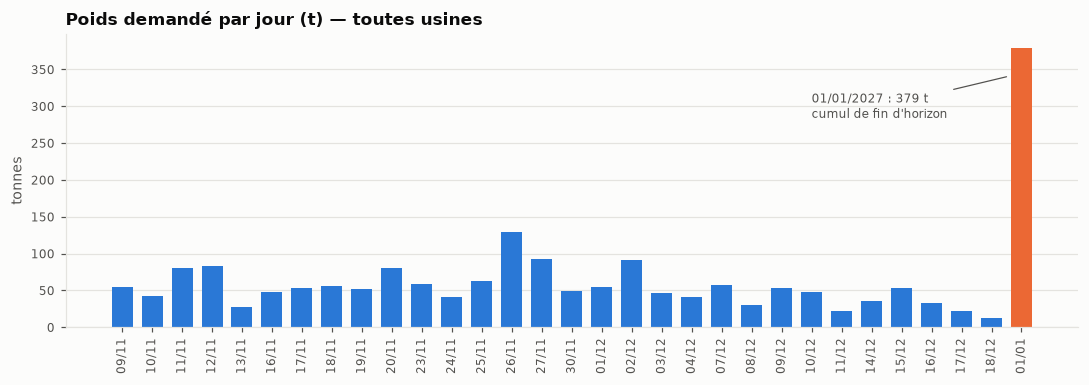

In [8]:
by_day = needs_raw.groupby("date")["weight"].sum() / 1000
last = by_day.index.max()
colors = [ACCENT if d == last else PRIMARY for d in by_day.index]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(by_day.index.strftime("%d/%m"), by_day.values, color=colors, width=0.7)
ax.set_title("Poids demandé par jour (t) — toutes usines")
ax.set_ylabel("tonnes")
ax.tick_params(axis="x", rotation=90)
ax.annotate(f"01/01/2027 : {by_day[last]:.0f} t\ncumul de fin d'horizon",
            xy=(len(by_day) - 1.4, by_day[last] * 0.9), xytext=(len(by_day) - 8, by_day[last] * 0.75),
            fontsize=8, color=TEXT_MUTED, arrowprops=dict(arrowstyle="-", color=TEXT_MUTED, lw=0.8))
plt.tight_layout(); plt.show()

### 2.3 `distances.csv`

In [9]:
sched_sup = schedule["supplier_id"].unique()
d_sched = distances[distances["supplier_id"].isin(sched_sup)]
print(f"{len(distances)} fournisseurs référencés, dont {len(d_sched)} présents dans le planning")
print(f"Distances manquantes : {distances['distance'].isna().sum()} au total, "
      f"dont {d_sched['distance'].isna().sum()} pour des fournisseurs du planning : "
      f"{', '.join(d_sched.loc[d_sched['distance'].isna(), 'supplier_id'])}")
print(f"Fournisseurs du planning absents du fichier : {len(set(sched_sup) - set(distances['supplier_id']))}")
d_sched["distance"].describe().to_frame("distance (km), fournisseurs du planning").T

156 fournisseurs référencés, dont 94 présents dans le planning
Distances manquantes : 11 au total, dont 2 pour des fournisseurs du planning : SUP_00047, SUP_00130
Fournisseurs du planning absents du fichier : 0


,count,mean,std,min,25%,50%,75%,max
"distance (km), fournisseurs du planning",92.00,62.91,35.50,6.00,33.00,60.50,82.25,149.00


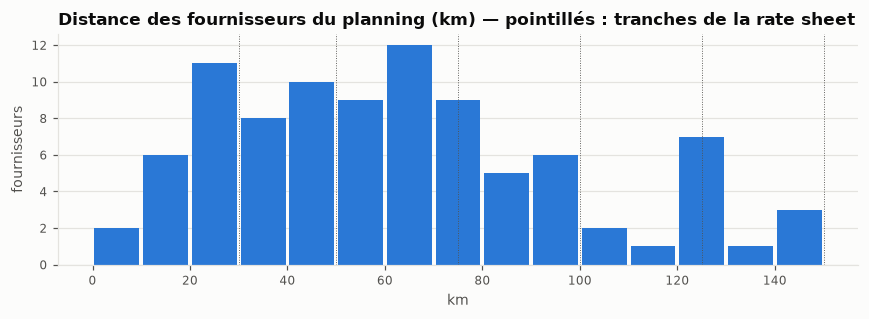

In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(d_sched["distance"].dropna(), bins=range(0, 160, 10), color=PRIMARY, rwidth=0.92)
for b in [30, 50, 75, 100, 125, 150]:
    ax.axvline(b, color=TEXT_MUTED, lw=0.6, ls=":")
ax.set_title("Distance des fournisseurs du planning (km) — pointillés : tranches de la rate sheet")
ax.set_xlabel("km"); ax.set_ylabel("fournisseurs")
plt.tight_layout(); plt.show()

Tous les fournisseurs du planning sont à moins de 150 km : seules les 6 premières tranches de distance de la *rate sheet* serviront.

### 2.4 `rate_sheet.pdf` — la grille tarifaire

Le PDF est lu automatiquement (`loaders.load_rate_sheet`), et non recopié à la main. La grille est ensuite validée en recalculant l'exemple fourni dans le document.

In [11]:
grid = rate_sheet.grid.copy()
grid.index = [f"≤ {k:g}" if np.isfinite(k) else "> 650" for k in grid.index]
grid.columns = [f"≤ {k:g}" if np.isfinite(k) else "> 4000" for k in grid.columns]
grid.index.name, grid.columns.name = "km \\ kg", None
grid

,≤ 50,≤ 100,≤ 200,≤ 300,≤ 400,≤ 500,≤ 750,≤ 1000,≤ 1500,≤ 2000,≤ 2500,≤ 3000,≤ 3500,≤ 4000,> 4000
km \ kg,,,,,,,,,,,,,,,
≤ 30,4.75,6.66,8.56,10.73,13.06,14.75,17.75,22.35,25.67,31.40,35.08,35.16,37.73,40.87,42.42
≤ 50,5.78,7.94,10.74,13.07,15.45,17.35,20.96,25.32,30.05,35.97,40.52,42.90,47.04,51.05,52.80
≤ 75,6.92,9.54,13.14,15.99,18.43,20.59,24.96,29.02,35.52,41.70,47.33,52.58,57.55,62.30,64.28
≤ 100,7.33,10.27,14.35,17.61,20.40,22.88,27.96,32.63,40.20,47.30,53.77,59.79,65.47,70.89,73.04
≤ 125,7.77,10.99,15.57,19.24,22.37,25.17,30.95,36.25,44.89,52.91,60.21,66.99,73.38,79.47,81.80
≤ 150,8.26,11.83,17.04,21.23,24.84,28.09,34.86,41.01,51.20,60.59,69.12,77.06,84.54,91.65,94.22
≤ 175,9.85,14.04,19.96,24.65,28.69,32.28,39.74,46.45,57.51,68.25,78.04,87.13,95.69,103.83,106.65
≤ 200,11.45,16.31,23.21,28.67,33.33,37.49,46.16,53.90,66.69,78.23,88.63,98.88,108.54,117.72,120.80
≤ 250,13.56,19.66,28.43,35.44,41.45,46.84,58.22,68.33,85.24,100.38,114.05,126.66,138.46,149.64,153.36


In [12]:
print(f"Marge : {rate_sheet.margin:.2%}   |   Diesel : × {rate_sheet.diesel_surcharge}   |   "
      f"Facteur prix = (1 + marge) × diesel = {rate_sheet.price_factor:.4f}   |   Valide depuis : {rate_sheet.valid_from:%d/%m/%Y}")

checks = pd.DataFrame([
    ("Exemple rate sheet", 300, 1000, 335.34),
    ("Exemple cahier des charges : SUP_00085 (121 km), camion de 11 660 kg", 121, 11660, 81.80 * rate_sheet.price_factor),
], columns=["cas", "km", "kg", "attendu_EUR"])
checks["coût_base"] = [rates.base_cost(rate_sheet, k, w) for k, w in zip(checks.km, checks.kg)]
checks["prix_calculé_EUR"] = [rates.transport_price(rate_sheet, k, w) for k, w in zip(checks.km, checks.kg)]
checks["ok"] = np.isclose(checks["prix_calculé_EUR"], checks["attendu_EUR"], atol=0.01)
checks

Marge : 239.23%   |   Diesel : × 1.1943   |   Facteur prix = (1 + marge) × diesel = 4.0514   |   Valide depuis : 01/08/2026


,cas,km,kg,attendu_EUR,coût_base,prix_calculé_EUR,ok
0,Exemple rate sheet,300,1000,335.34,82.77,335.34,True
1,"Exemple cahier des charges : SUP_00085 (121 km), camion de 11 660 kg",121,11660,331.41,81.80,331.41,True


Lecture de la grille : les bornes sont des **maxima inclusifs** (« up to km », « up to kg »). Un envoi de 121 km est donc lu sur la ligne ≤ 125 km. Les deux exemples des documents sont retrouvés au centime près.

### 2.5 Relations entre les trois sources

```
 released_schedule.csv                            distances.csv
 ┌───────────────────────────┐   supplier_id     ┌──────────────────┐
 │ date                      │   N ────────► 1   │ supplier_id      │
 │ supplier_id ──────────────┼──────────────────►│ distance (km)    │
 │ plant ──► unloading_point │                   └────────┬─────────┘
 │ material                  │                            │ tranche km
 │ schedule_quantity         │                            ▼
 │ weight, volume            │   Σ poids d'un    ┌──────────────────────────┐
 └───────────────────────────┘   envoi ────────► │ rate_sheet.pdf           │
                                 tranche kg      │ coût(km, kg) × 4,0514    │
                                                 └──────────────────────────┘
```

- **Planning → distances** : jointure N:1 sur `supplier_id`. La distance dépend du fournisseur seul, pas de l'usine : elle est mesurée jusqu'au point de consolidation.
- **Distances → rate sheet** : la distance donne la **ligne** de la grille.
- **Planning → rate sheet** : le poids donne la **colonne**. Ce n'est pas le poids d'une ligne de besoin mais celui d'un **envoi**, c'est-à-dire la somme des lignes chargées dans un camion. Le coût dépend donc directement de la façon dont on regroupe : c'est le levier de la consolidation.

#### Cardinalités entre les entités du planning

In [13]:
quality.cardinalities(schedule)

,n_gauche,lies_a_plusieurs,moyenne,max,type
relation,,,,,
Fournisseur → usines,94,52,1.93,4,1:N
Usine → fournisseurs,4,4,45.25,64,1:N
Usine → quais,4,4,12.50,25,1:N
Quai → usines,50,0,1.00,1,1:1
Couple → materials,181,134,7.03,63,1:N
Couple → quais,181,98,2.21,11,1:N
Material → fournisseurs,1158,16,1.01,3,1:N
Material → usines,1158,101,1.09,3,1:N
Material × usine → fournisseurs,1268,4,1.00,2,1:N


Lecture :

- **Quai → usine est 1:1.** Un quai appartient à une seule usine. Un camion dédié à une usine peut donc desservir plusieurs de ses quais, comme dans l'exemple du cahier des charges (ULP_0010 et ULP_0050 dans le même camion).
- **52 fournisseurs sur 94 livrent plusieurs usines** (jusqu'à 4). La règle R1 (un camion = une usine) les oblige à envoyer des camions distincts. Ce sont des couples indépendants. Une tournée multi-usines serait un levier supplémentaire, hors du périmètre fixé.
- **Couple → materials** : 7 *materials* en moyenne et jusqu'à 63. C'est le contenu potentiel d'un camion (sortie 2).
- **Le material seul n'est pas une clé.** Une même référence peut venir de plusieurs fournisseurs (16 cas) ou aller vers plusieurs usines (101 cas). On a même 4 cas de double source pour une même usine, et 101 cas où une même pièce va vers plusieurs quais de la même usine. La clé d'un besoin est donc bien `(date, fournisseur, material, usine, quai)`, et l'absence de doublon sur cette clé a été vérifiée (contrôle S01).

#### Intégrité référentielle entre les fichiers

In [14]:
quality.referential_integrity(schedule, distances, rate_sheet)

,jointure,controle,couverts,total,couverture_pct
0,schedule → distances,Fournisseurs du planning présents dans distances,94,94,100.00
1,schedule → distances,… avec une distance renseignée,92,94,97.90
2,distances → schedule,Fournisseurs de distances utilisés par le planning,94,156,60.30
3,distances → rate_sheet,Distances du planning dans les tranches fermées (≤ 650 km),92,92,100.00
4,schedule → rate_sheet,Livraisons actuelles (couple × jour) ≤ 4000 kg,1641,1731,94.80


- Tous les fournisseurs du planning existent dans `distances.csv`, mais 2 n'ont pas de distance (règle d'imputation en section 3).
- Le fichier `distances.csv` est un référentiel plus large que le planning : 62 fournisseurs n'y sont pas utilisés, sans impact.
- Toutes les distances du planning tombent dans les tranches fermées de la grille. Une partie des livraisons dépasse 4 000 kg et relève de la tranche ouverte (hypothèse H3).

#### Où se situent les livraisons actuelles dans la grille tarifaire ?

On croise les trois sources : chaque livraison actuelle (couple × jour) est placée dans la grille selon la distance de son fournisseur et son poids.

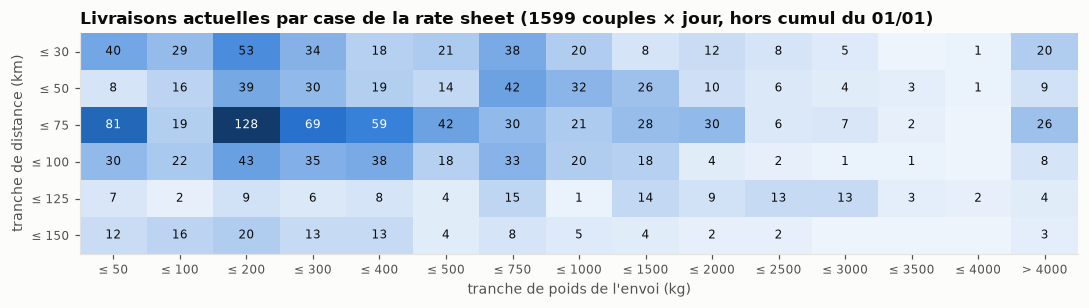

Livraisons ≤ 1 000 kg : 80%   |   > 4 000 kg : 4%


In [15]:
from matplotlib.colors import LinearSegmentedColormap

cur = (needs_raw.merge(distances, on="supplier_id", how="left")
       .groupby(config.COUPLE_KEY + ["date"]).agg(weight=("weight", "sum"), distance=("distance", "first"))
       .reset_index())
cur = cur[(cur["date"] != last) & cur["distance"].notna() & (cur["weight"] > 0)]
cur["km"] = rates.brackets(rate_sheet.grid.index, cur["distance"])
cur["kg"] = rates.brackets(rate_sheet.grid.columns, cur["weight"])
mat = pd.crosstab(cur["km"], cur["kg"]).reindex(columns=rate_sheet.grid.columns, fill_value=0)

cmap = LinearSegmentedColormap.from_list("seq", ["#eef4fc", PRIMARY, "#123a6b"])
fig, ax = plt.subplots(figsize=(10, 2.9))
ax.imshow(mat.values, cmap=cmap, aspect="auto")
ax.set_xticks(range(mat.shape[1]), [f"≤ {c:g}" if np.isfinite(c) else "> 4000" for c in mat.columns])
ax.set_yticks(range(mat.shape[0]), [f"≤ {k:g}" for k in mat.index])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=8,
                    color="white" if v > mat.values.max() * 0.45 else TEXT)
ax.grid(False)
ax.set_xlabel("tranche de poids de l'envoi (kg)"); ax.set_ylabel("tranche de distance (km)")
ax.set_title(f"Livraisons actuelles par case de la rate sheet ({len(cur)} couples × jour, hors cumul du 01/01)")
plt.tight_layout(); plt.show()

print(f"Livraisons ≤ 1 000 kg : {(cur['weight'] <= 1000).mean():.0%}   |   > 4 000 kg : {(cur['weight'] > 4000).mean():.0%}")

In [16]:
# Prix au kg selon le poids de l'envoi, sur la tranche de distance médiane (≤ 75 km)
row = rate_sheet.grid.loc[75.0]
cols = [50.0, 300.0, 1000.0, 4000.0, np.inf]
per_kg = pd.DataFrame({"poids de l'envoi (kg)": [50, 300, 1000, 4000, config.TRUCK_MAX_WEIGHT_KG],
                       "prix de l'envoi (EUR)": [row[c] * rate_sheet.price_factor for c in cols]})
per_kg["prix au kg (EUR/kg)"] = per_kg["prix de l'envoi (EUR)"] / per_kg["poids de l'envoi (kg)"]
per_kg.index = ["50 kg", "300 kg", "1 t", "4 t", "camion plein (24,5 t, tarif > 4000)"]
print(f"Un envoi de 50 kg coûte {per_kg.iloc[0, 2] / per_kg.iloc[-1, 2]:.0f}× plus cher au kg qu'un camion plein.")
per_kg

Un envoi de 50 kg coûte 53× plus cher au kg qu'un camion plein.


,poids de l'envoi (kg),prix de l'envoi (EUR),prix au kg (EUR/kg)
50 kg,50.00,28.04,0.56
300 kg,300.00,64.78,0.22
1 t,1 000.00,117.57,0.12
4 t,4 000.00,252.40,0.06
"camion plein (24,5 t, tarif > 4000)",24 500.00,260.43,0.01


La grande majorité des livraisons actuelles se trouve dans les colonnes de gauche (envois légers), là où le **prix au kg est le plus élevé**. Le tarif est fortement dégressif avec le poids et devient forfaitaire au-delà de 4 000 kg. Regrouper plusieurs livraisons légères en un envoi plus lourd fait donc baisser mécaniquement le coût total. Ce croisement des trois sources confirme le potentiel d'économie, qui sera chiffré au Milestone 2.

### 2.6 Valeurs manquantes

In [17]:
pd.concat({
    "schedule (toutes lignes)": quality.missing_values(schedule),
    "schedule (quantité > 0)": quality.missing_values(needs_raw),
    "distances": quality.missing_values(distances),
})

manquants  pct
schedule (toutes lignes) weight          169 2.95
                         volume          147 2.57
schedule (quantité > 0)  weight          139 2.91
                         volume          119 2.50
distances                distance         11 7.05

In [18]:
miss = needs_raw[needs_raw["weight"].isna() | needs_raw["volume"].isna()]
print(f"{len(miss)} lignes avec besoin ont un poids ou un volume manquant ; "
      f"{(miss['weight'].isna() & miss['volume'].isna()).sum()} n'ont ni l'un ni l'autre.")
has_weight_elsewhere = miss["material"].isin(needs_raw.dropna(subset=["weight"])["material"])
print(f"Seules {has_weight_elsewhere[miss['weight'].isna()].sum()} lignes à poids manquant concernent un material "
      f"dont le poids est connu ailleurs dans le planning → un repli au-delà du material est nécessaire.")
miss.groupby(config.COUPLE_KEY).size().sort_values(ascending=False).head(8).rename("lignes incomplètes").to_frame()

139 lignes avec besoin ont un poids ou un volume manquant ; 119 n'ont ni l'un ni l'autre.
Seules 21 lignes à poids manquant concernent un material dont le poids est connu ailleurs dans le planning → un repli au-delà du material est nécessaire.


lignes incomplètes
supplier_id plant                      
SUP_00129   PLT_003                  24
            PLT_001                  19
SUP_00001   PLT_004                  17
SUP_00117   PLT_002                  12
SUP_00153   PLT_004                  11
SUP_00046   PLT_002                   6
SUP_00107   PLT_002                   5
SUP_00145   PLT_002                   5

Les valeurs manquantes sont **concentrées sur quelques couples** : SUP_00129 en représente à lui seul près d'un tiers (43 lignes sur 139). Il ne s'agit donc pas d'un bruit aléatoire mais de *materials* dont la fiche logistique n'est pas renseignée. C'est un point à remonter au métier.

### 2.7 Incohérences et points d'attention

#### 2.7.1 La colonne `volume` ne suit pas la quantité (H1)

In [19]:
varying = needs_raw.groupby("material").filter(lambda g: g["schedule_quantity"].nunique() > 1)
ex = (varying.groupby("material")
      .agg(qte_min=("schedule_quantity", "min"), qte_max=("schedule_quantity", "max"),
           vol_min=("volume", "min"), vol_max=("volume", "max"),
           poids_min=("weight", "min"), poids_max=("weight", "max"))
      .query("vol_min == vol_max").head(6))
display(ex)
print("Valeurs de volume les plus fréquentes (m³) :")
print(schedule["volume"].round(4).value_counts().head(6).to_string())

,qte_min,qte_max,vol_min,vol_max,poids_min,poids_max
material,,,,,,
MAT_000002,300.00,600.00,0.01,0.01,1.67,3.24
MAT_000003,60.00,180.00,0.57,0.57,106.20,124.20
MAT_000004,160.00,320.00,1.20,1.20,193.40,233.30
MAT_000006,240.00,480.00,1.20,1.20,222.80,445.70
MAT_000007,300.00,900.00,0.42,0.42,236.10,708.30
MAT_000008,110.00,900.00,0.42,0.42,80.20,405.60


Valeurs de volume les plus fréquentes (m³) :
volume
1.20    1179
0.02     666
0.01     564
0.42     532
0.41     519
0.89     463


Pour un même *material*, le **poids** varie avec la quantité, mais le **volume** reste identique. Le volume est aussi renseigné sur les lignes à quantité nulle, et ses valeurs les plus fréquentes sont des volumes d'emballage standard (1,2 m³ correspond à une palette).

**Conclusion :** `volume` ressemble au volume d'une unité de manutention plutôt qu'au volume de la ligne. Le nombre d'unités par ligne n'étant pas fourni, on suit la convention du cahier des charges, qui somme cette colonne (H1). C'est **la première question à poser au métier**.

L'enjeu est réel : même avec cette convention, le volume est déjà la contrainte la plus serrée pour environ 30 % des livraisons actuelles (§ 5.3). Si la colonne sous-estime le vrai volume, la capacité des camions sera surestimée.

#### 2.7.2 La dernière date est un cumul de fin d'horizon (H2)

In [20]:
daily = needs_raw.groupby("date").agg(lignes=("line_id", "size"), poids_t=("weight", lambda w: w.sum() / 1000))
print(f"Jour médian : {daily['lignes'].median():.0f} lignes, {daily['poids_t'].median():.1f} t")
print(f"01/01/2027  : {daily.loc[last, 'lignes']} lignes, {daily.loc[last, 'poids_t']:.1f} t "
      f"({daily.loc[last, 'poids_t'] / daily['poids_t'].median():.1f}× le jour médian)")
all_days = pd.bdate_range(schedule["date"].min(), schedule["date"].max())
print("Jours ouvrés sans aucune ligne :", ", ".join(all_days.difference(schedule["date"].unique()).strftime("%d/%m")))

Jour médian : 123 lignes, 52.8 t
01/01/2027  : 379 lignes, 379.0 t (7.2× le jour médian)
Jours ouvrés sans aucune ligne : 21/12, 24/12, 25/12, 29/12, 31/12


Le 01/01/2027 porte environ 7 fois la charge d'un jour normal. Il arrive après une série de jours vides (période des fêtes), alors que c'est un jour férié. C'est la signature d'un **bucket cumulé** : tout ce qui est prévu au-delà de l'horizon ferme est reporté sur la dernière date du programme.

**Décision :** on conserve ces lignes avec l'indicateur `is_horizon_bucket`, et on les exclut par défaut de la consolidation hebdomadaire. Il serait absurde de « consolider » 379 t sur un jour fictif.

#### 2.7.3 Poids unitaire non constant (H4)

In [21]:
ratio = quality.unit_weight_ratio(needs_raw)
print(f"Lignes dont le poids unitaire diffère de la médiane du material : {(~np.isclose(ratio, 1)).sum()} "
      f"/ {ratio.notna().sum()}")
print(f"Dont écart > {config.UNIT_WEIGHT_OUTLIER_FACTOR:g}× : "
      f"{((ratio > config.UNIT_WEIGHT_OUTLIER_FACTOR) | (ratio < 1 / config.UNIT_WEIGHT_OUTLIER_FACTOR)).sum()}")
(needs_raw.assign(poids_unitaire=needs_raw["weight"] / needs_raw["schedule_quantity"], ratio_mediane=ratio)
 .loc[lambda d: d["ratio_mediane"].gt(10)]
 .sort_values("ratio_mediane", ascending=False)
 [["date", "supplier_id", "material", "schedule_quantity", "weight", "poids_unitaire", "ratio_mediane"]].head(6))

Lignes dont le poids unitaire diffère de la médiane du material : 1219 / 4630
Dont écart > 10× : 41


,date,supplier_id,material,schedule_quantity,weight,poids_unitaire,ratio_mediane
1265,2026-12-16,SUP_00145,MAT_000647,200.00,93.90,0.47,30.99
1266,2027-01-01,SUP_00145,MAT_000647,200.00,93.90,0.47,30.99
4640,2026-11-27,SUP_00102,MAT_000523,100.00,94.90,0.95,23.55
1497,2026-11-27,SUP_00080,MAT_000466,1.00,142.50,142.50,17.28
1503,2026-11-27,SUP_00080,MAT_000714,1.00,142.50,142.50,17.28
4839,2026-11-26,SUP_00080,MAT_000354,120.00,161.80,1.35,17.08


Les écarts touchent surtout les **petites quantités**. Exemple : 1 pièce pour 142,5 kg, soit le poids d'un conteneur vide plus une pièce. Le poids est donc un **poids brut, emballage compris**, ce qui est cohérent avec la *rate sheet*, facturée « by gross weight ». Ces lignes sont **signalées mais pas corrigées** : les « corriger » ferait disparaître un poids réellement transporté.

#### 2.7.4 Lignes plus lourdes qu'un camion

In [22]:
heavy = needs_raw[needs_raw["weight"] > config.TRUCK_MAX_WEIGHT_KG]
display(heavy[["date", "supplier_id", "plant", "material", "schedule_quantity", "weight", "volume"]])
day_w = needs_raw.groupby(config.COUPLE_KEY + ["date"])["weight"].sum()
print(f"Couples × jour au-delà de 24,5 t : {(day_w > config.TRUCK_MAX_WEIGHT_KG).sum()} "
      f"(dont {(day_w[day_w > config.TRUCK_MAX_WEIGHT_KG].index.get_level_values('date') == last).sum()} sur le cumul du 01/01)")

,date,supplier_id,plant,material,schedule_quantity,weight,volume
610,2027-01-01,SUP_00117,PLT_004,MAT_000700,5 320.00,58 267.30,1.14
5015,2026-12-15,SUP_00074,PLT_003,MAT_001164,5 670.00,26 905.20,0.84


Couples × jour au-delà de 24,5 t : 8 (dont 3 sur le cumul du 01/01)


Ces besoins ne tiennent pas dans un seul camion, même sans consolidation. Le moteur devra savoir **découper un besoin sur plusieurs camions**. Une seule ligne, et non pas seulement un jour, peut dépasser 24,5 t (58 t pour MAT_000700). Ce cas limite sera à tester au Milestone 4.

### 2.8 Registre des contrôles qualité

Tous les contrôles sont codés dans `quality.run_quality_checks`. Ils sont rejoués à chaque exécution et exportés dans `data/processed/quality_report.csv`.

In [23]:
qreport = quality.run_quality_checks(schedule, distances, rate_sheet)

def color_severity(v):
    return {"CRITIQUE": "background-color:#f8d7d7", "ATTENTION": "background-color:#fbeccc",
            "INFO": "background-color:#e3eefb", "OK": "color:#52514e"}.get(v, "")

(qreport.style.map(color_severity, subset=["gravite"])
 .format({"pct": "{:.2f}"}).hide(axis="index"))

id,source,controle,n_concernes,pct,gravite,detail,regle_de_traitement
S01,schedule,"Doublons sur la clé (date, fournisseur, material, usine, quai)",0,0.00,OK,,
S02,schedule,Lignes sans besoin (quantité = 0),959,16.74,INFO,,Écartées : rien à livrer (filtre quantité > 0)
S03,schedule,"Valeurs négatives (quantité, poids, volume)",0,0.00,OK,,
S04,schedule,Poids manquant sur une ligne avec besoin,139,2.91,ATTENTION,,"Imputation : poids unitaire médian du material x quantité, sinon poids médian d'une ligne du couple, sinon médiane globale ; tracé dans `weight_source`"
S05,schedule,Volume manquant sur une ligne avec besoin,119,2.50,ATTENTION,,"Imputation : volume du material (constant par material), sinon médiane du couple, sinon médiane globale ; tracé dans `volume_source`"
S06,schedule,Quantité > 0 mais poids = 0,0,0.00,OK,,
S07,schedule,Quantité = 0 mais volume > 0,931,16.25,INFO,Le volume est renseigné même sans besoin,Sans effet (lignes écartées) ; indique que `volume` est un attribut du material
S08,schedule,Volume identique quelle que soit la quantité (materials à quantité variable),397,85.38,ATTENTION,"Valeurs typiques d'emballage (1,2 m³ = palette) : le volume semble être celui d'une unité de manutention",Hypothèse à valider : `volume` utilisé tel quel comme volume de la ligne (convention du cahier des charges)
S09,schedule,Besoin un samedi ou un dimanche,0,0.00,OK,,
S10,schedule,Besoin un jour férié,487,10.21,INFO,"01/01/2027, 11/11/2026",Conservé et signalé (`is_holiday`) ; le moteur évitera de livrer ces jours-là


In [24]:
qreport["gravite"].value_counts().reindex(["CRITIQUE", "ATTENTION", "INFO", "OK"], fill_value=0).to_frame("contrôles")

,contrôles
gravite,
CRITIQUE,0
ATTENTION,6
INFO,8
OK,14


**Bilan :** aucune anomalie critique. Il n'y a ni doublon, ni valeur négative, ni version multiple, ni week-end, ni quai partagé entre usines, et la grille tarifaire est complète, croissante et validée par les deux exemples. Les points d'attention relèvent tous d'une règle explicite, décrite en section 3.

## 3. Règles de nettoyage

| Anomalie (contrôle) | Règle retenue | Justification | Traçabilité |
|---|---|---|---|
| Quantité = 0 (S02) | Ligne écartée | Aucun besoin à livrer | Journal du pipeline |
| Poids manquant (S04) | Imputation hiérarchique : ① poids unitaire médian du *material* × quantité → ② poids médian d'une ligne du couple → ③ médiane globale | ① est le plus précis, mais ne couvre que 21 lignes ; ② respecte l'ordre de grandeur du fournisseur | `weight_source` |
| Volume manquant (S05) | ① volume du *material* (constant par *material*, y compris sur les lignes à quantité 0) → ② médiane du couple → ③ médiane globale | Le volume est un attribut du *material* (H1) | `volume_source` |
| Distance manquante (D03) | Médiane des distances des fournisseurs du planning (60,5 km) | Valeur centrale. La médiane de tout le fichier (55 km) tombe dans la même tranche tarifaire (≤ 75 km) : le choix n'a pas d'impact sur le coût | `distance_source` |
| Volume « d'emballage » (S08) | Utilisé tel quel (H1) | Convention du cahier des charges, en attente de validation | Hypothèse H1 |
| Cumul de fin d'horizon (S11) | Conservé et signalé ; exclu par défaut de la consolidation hebdomadaire | Ce n'est pas un besoin journalier réel | `is_horizon_bucket` |
| Jour férié avec besoin (S10) | Conservé et signalé | La date du besoin reste vraie ; c'est le jour de **livraison** qui devra éviter un férié | `is_holiday` |
| Poids unitaire atypique (S14) | Signalé, non corrigé | Poids brut avec emballage (H4) | `unit_weight_outlier` |
| Ligne > 24,5 t (S12) | Conservée et signalée | Réelle ; le moteur la répartira sur plusieurs camions | `line_exceeds_truck` |
| Couple sans besoin (S19) | Exclu | Rien à livrer | Journal du pipeline |

Le cas limite d'un poids nul avec une quantité positive (S06, absent ici) est traité comme un poids manquant. Toutes ces règles sont paramétrables dans `config.py`.

## 4. Pipeline de nettoyage et d'agrégation

`preparation.prepare()` enchaîne des étapes élémentaires, chacune testable séparément :

```
schedule brut ─► dernière version ─► quantité > 0 ─► imputation poids ─► imputation volume
             ─► distances ─► calendrier (semaine, jour, férié, cumul) ─► signalement des anomalies
             ─► lignes nettoyées ─► agrégation couple × jour ─► synthèse par couple
```

In [25]:
result = preparation.prepare(schedule, distances)
result.log_table

,etape,lignes,commentaire
0,Chargement,5728,Fichier brut
1,Dernière version du programme,5728,
2,Filtre quantité > 0,4769,Lignes sans besoin écartées
3,Imputation du poids,4769,139 lignes imputées
4,Imputation du volume,4769,119 lignes imputées
5,Ajout des distances,4769,5 lignes à distance imputée
6,Calendrier,4769,379 lignes dans le cumul de fin d'horizon
7,Signalement des anomalies,4769,42 poids unitaires atypiques
8,Agrégation couple x jour,1731,Livraisons actuelles
9,Synthèse par couple,181,Couples avec au moins un besoin


### Impact des imputations

L'imputation ne doit pas peser lourd dans les résultats. On mesure donc la part du poids total qui provient d'une valeur imputée.

In [26]:
L = result.lines
impact = (L.groupby("weight_source").agg(lignes=("line_id", "size"), poids_t=("weight", lambda w: w.sum() / 1000))
          .reindex(["source", "material", "couple", "global"]).dropna())
impact["% lignes"] = 100 * impact["lignes"] / impact["lignes"].sum()
impact["% poids"] = 100 * impact["poids_t"] / impact["poids_t"].sum()
display(impact)

vol_impact = L["volume_source"].value_counts().reindex(["source", "material", "couple", "global"]).dropna().to_frame("lignes (volume)")
display(vol_impact)

per_couple = result.couples.sort_values("imputed_weight_share", ascending=False)
print("Couples les plus dépendants de l'imputation du poids :")
per_couple.loc[per_couple["imputed_weight_share"] > 0.2,
               ["supplier_id", "plant", "n_lines", "total_weight", "imputed_weight_share"]].head(10)

,lignes,poids_t,% lignes,% poids
weight_source,,,,
source,4630,1 994.34,97.09,96.99
material,21,9.31,0.44,0.45
couple,92,48.75,1.93,2.37
global,26,3.81,0.55,0.19


,lignes (volume)
volume_source,
source,4650
material,26
couple,67
global,26


Couples les plus dépendants de l'imputation du poids :


,supplier_id,plant,n_lines,total_weight,imputed_weight_share
34,SUP_00108,PLT_001,2,292.80,1.00
99,SUP_00127,PLT_002,2,292.80,1.00
77,SUP_00077,PLT_002,3,439.20,1.00
70,SUP_00054,PLT_002,2,292.80,1.00
55,SUP_00018,PLT_002,3,439.20,1.00
179,SUP_00153,PLT_004,11,1 610.40,1.00
103,SUP_00133,PLT_002,3,439.20,1.00
141,SUP_00001,PLT_004,26,4 697.80,0.65
39,SUP_00129,PLT_001,32,20 568.30,0.54
95,SUP_00117,PLT_002,21,18 861.81,0.43


Moins de 3 % des lignes sont imputées, et elles représentent une faible part du poids total : l'effet global est marginal. Quelques couples, en revanche, reposent largement sur des poids imputés. Leurs résultats seront présentés avec un **indicateur de fiabilité** dans les sorties du moteur.

## 5. Dataset consolidé, prêt pour la partie algorithmique

### 5.1 Contrôles d'acceptation

Ces contrôles garantissent que le pipeline n'a **ni perdu, ni créé, ni modifié** de besoin, en dehors des imputations tracées.

In [27]:
acceptance = preparation.validate(result, schedule)
display(acceptance)
assert acceptance["ok"].all(), "Un contrôle d'acceptation a échoué"

,controle,ok
0,Aucun besoin perdu (une ligne par besoin source),True
1,Quantité totale conservée,True
2,line_id unique et présent dans la source,True
3,"Aucune valeur manquante (poids, volume, distance)",True
4,Poids et volumes strictement positifs,True
5,Poids non imputés identiques à la source,True
6,Uniquement des jours ouvrés,True
7,Poids agrégé = somme des lignes,True
8,Une seule usine par couple x jour,True


### 5.2 Les trois tables produites

**`needs_clean`** contient un besoin par ligne, c'est l'entrée du moteur de consolidation.

In [28]:
result.lines.head()

,line_id,date,week_start,iso_year,iso_week,weekday,weekday_name,supplier_id,plant,unloading_point,material,schedule_quantity,weight,weight_source,volume,volume_source,distance,distance_source,is_holiday,is_horizon_bucket,unit_weight_outlier,line_exceeds_truck,is_imputed
0,5457,2026-11-26,2026-11-23,2026,48,3,Jeudi,SUP_00001,PLT_004,ULP_0010,MAT_000077,60.00,158.20,source,0.89,source,47.00,source,False,False,False,False,False
1,5382,2026-11-26,2026-11-23,2026,48,3,Jeudi,SUP_00001,PLT_004,ULP_0010,MAT_000319,54.00,223.70,source,1.20,source,47.00,source,False,False,False,False,False
2,5398,2026-11-26,2026-11-23,2026,48,3,Jeudi,SUP_00001,PLT_004,ULP_0010,MAT_000333,176.00,180.00,couple,0.42,source,47.00,source,False,False,False,False,True
3,5504,2026-11-26,2026-11-23,2026,48,3,Jeudi,SUP_00001,PLT_004,ULP_0010,MAT_000893,54.00,138.30,source,0.89,source,47.00,source,False,False,False,False,False
4,5399,2026-11-27,2026-11-23,2026,48,4,Vendredi,SUP_00001,PLT_004,ULP_0010,MAT_000333,320.00,180.00,couple,0.42,source,47.00,source,False,False,False,False,True


**`deliveries_couple_day`** donne la charge par couple × jour, c'est-à-dire la **situation actuelle** (une livraison par jour de besoin). Elle servira de *baseline* au Milestone 2.

In [29]:
result.couple_day.head()

,supplier_id,plant,date,n_lines,n_materials,n_unloading_points,quantity,weight,volume,distance,n_imputed_lines,week_start,weekday,is_holiday,is_horizon_bucket,fill_weight,fill_volume,min_trucks
0,SUP_00001,PLT_004,2026-11-26,4,4,1,344.00,700.20,3.39,47.00,1,2026-11-23,3,False,False,0.03,0.03,1
1,SUP_00001,PLT_004,2026-11-27,1,1,1,320.00,180.00,0.42,47.00,1,2026-11-23,4,False,False,0.01,0.00,1
2,SUP_00001,PLT_004,2026-11-30,1,1,1,320.00,180.00,0.42,47.00,1,2026-11-30,0,False,False,0.01,0.00,1
3,SUP_00001,PLT_004,2026-12-01,1,1,1,368.00,180.00,0.42,47.00,1,2026-11-30,1,False,False,0.01,0.00,1
4,SUP_00001,PLT_004,2026-12-02,1,1,1,104.00,180.00,0.42,47.00,1,2026-11-30,2,False,False,0.01,0.00,1


**`couples`** donne une ligne par couple fournisseur × usine (distance, volumétrie, rythme actuel).

In [30]:
result.couples.head()

,supplier_id,plant,distance,distance_source,n_materials,n_unloading_points,n_lines,total_weight,total_volume,imputed_weight,n_delivery_days,n_active_weeks,weight_firm,median_delivery_weight,median_fill_weight,deliveries_per_week,weekly_weight,imputed_weight_share
0,SUP_00003,PLT_001,83.00,source,4,4,10,870.99,1.74,0.00,7.00,4.00,711.80,93.50,0.00,1.17,118.63,0.00
1,SUP_00005,PLT_001,46.00,source,5,1,11,19 929.70,51.84,8 282.40,5.00,5.00,12 469.60,2 070.60,0.08,0.83,2 078.27,0.42
2,SUP_00010,PLT_001,56.00,source,1,1,4,33.68,0.07,0.00,4.00,3.00,33.68,5.63,0.00,0.67,5.61,0.00
3,SUP_00014,PLT_001,54.00,source,27,6,55,2 713.44,2.59,0.00,18.00,6.00,2 058.08,71.89,0.00,3.00,343.01,0.00
4,SUP_00016,PLT_001,96.00,source,2,2,4,155.28,0.08,0.00,4.00,4.00,155.28,45.55,0.00,0.67,25.88,0.00


### 5.3 Contrôle de cohérence avec le cahier des charges

On retrouve les ordres de grandeur annoncés dans le document du projet. Cela confirme que les données sont comprises de la même façon.

In [31]:
cd = result.couple_day
raw_cd = needs_raw.groupby(config.COUPLE_KEY + ["date"])[["weight", "volume"]].sum()
pd.DataFrame({
    "cahier des charges": ["185", "1 731", "316 kg", "1,3 %", "1,1 m³", "94 / 4", "55 km"],
    "calculé (données brutes)": [
        schedule.groupby(config.COUPLE_KEY).ngroups, len(raw_cd), f"{raw_cd['weight'].median():.0f} kg",
        f"{raw_cd['weight'].median() / config.TRUCK_MAX_WEIGHT_KG:.1%}", f"{raw_cd['volume'].median():.2f} m³",
        f"{schedule['supplier_id'].nunique()} / {schedule['plant'].nunique()}", f"{d_sched['distance'].median():.0f} km"],
    "calculé (après imputation)": [
        f"{result.couples.shape[0]} actifs", len(cd), f"{cd['weight'].median():.0f} kg",
        f"{cd['fill_weight'].median():.1%}", f"{cd['volume'].median():.2f} m³", "", ""],
}, index=["Couples fournisseur × usine", "Livraisons (couple × jour)", "Poids médian d'une livraison",
          "Remplissage médian (poids)", "Volume médian d'une livraison", "Fournisseurs / usines", "Distance médiane (fournisseurs du planning)"])

,cahier des charges,calculé (données brutes),calculé (après imputation)
Couples fournisseur × usine,185,185,181 actifs
Livraisons (couple × jour),1 731,1731,1731
Poids médian d'une livraison,316 kg,316 kg,335 kg
Remplissage médian (poids),"1,3 %",1.3%,1.4%
Volume médian d'une livraison,"1,1 m³",1.14 m³,1.20 m³
Fournisseurs / usines,94 / 4,94 / 4,
Distance médiane (fournisseurs du planning),55 km,60 km,


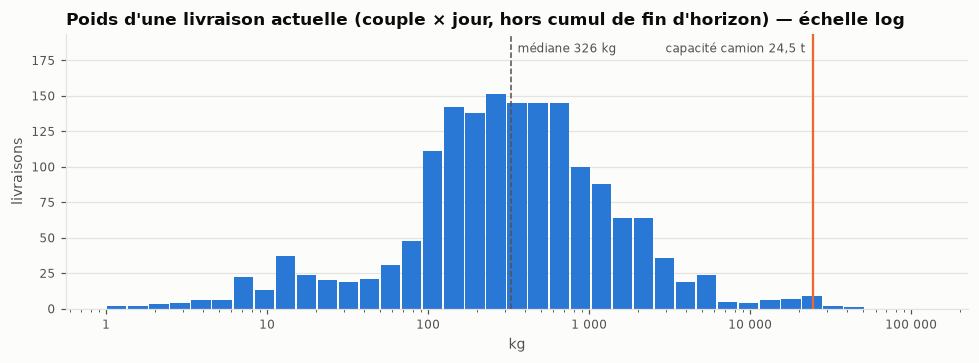

Livraisons où le volume est plus contraignant que le poids : 29.9%


In [32]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.logspace(0, np.log10(cd["weight"].max() * 1.1), 40)
firm_w = cd.loc[~cd["is_horizon_bucket"], "weight"]
ax.hist(firm_w, bins=bins, color=PRIMARY, rwidth=0.92)
ax.set_xscale("log")
top = ax.get_ylim()[1] * 1.22
ax.set_ylim(0, top)
ax.axvline(config.TRUCK_MAX_WEIGHT_KG, color=ACCENT, lw=1.5)
ax.text(config.TRUCK_MAX_WEIGHT_KG * 0.9, top * 0.97, "capacité camion 24,5 t",
        ha="right", va="top", fontsize=8, color=TEXT_MUTED)
ax.axvline(firm_w.median(), color=TEXT_MUTED, lw=1, ls="--")
ax.text(firm_w.median() * 1.1, top * 0.97, f"médiane {firm_w.median():.0f} kg",
        va="top", fontsize=8, color=TEXT_MUTED)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " ")))
ax.set_title("Poids d'une livraison actuelle (couple × jour, hors cumul de fin d'horizon) — échelle log")
ax.set_xlabel("kg"); ax.set_ylabel("livraisons")
plt.tight_layout(); plt.show()

share_vol_binding = (cd["fill_volume"] > cd["fill_weight"]).mean()
print(f"Livraisons où le volume est plus contraignant que le poids : {share_vol_binding:.1%}")

L'écart d'ordre de grandeur entre une livraison typique (quelques centaines de kg) et la capacité d'un camion (24,5 t) confirme le **potentiel de consolidation**. Il sera quantifié au Milestone 2.

### 5.4 Export

Toutes les sorties sont régénérées à l'identique à chaque exécution : mêmes entrées et mêmes paramètres donnent les mêmes fichiers.

In [33]:
files = preparation.save_outputs(result, rate_sheet, qreport)
pd.DataFrame({"fichier": [p.relative_to(ROOT).as_posix() for p in files.values()],
              "lignes": [len(pd.read_csv(p)) for p in files.values()]}, index=list(files))

,fichier,lignes
lines,data/processed/needs_clean.csv,4769
couple_day,data/processed/deliveries_couple_day.csv,1731
couples,data/processed/couples.csv,181
rate_sheet,data/processed/rate_sheet.csv,210
rate_params,data/processed/rate_params.csv,1
quality,data/processed/quality_report.csv,28
log,data/processed/pipeline_log.csv,10


### 5.5 Dictionnaire des données produites — `needs_clean.csv`

| Colonne | Description |
|---|---|
| `line_id` | N° de ligne dans `released_schedule.csv` (traçabilité) |
| `date`, `week_start`, `iso_year`, `iso_week`, `weekday`, `weekday_name` | Date du besoin et calendrier (`week_start` = lundi de la semaine) |
| `supplier_id`, `plant`, `unloading_point`, `material` | Clés métier |
| `schedule_quantity` | Quantité demandée (> 0) |
| `weight`, `weight_source` | Poids brut (kg) et origine : `source`, `material`, `couple`, `global` |
| `volume`, `volume_source` | Volume (m³, hypothèse H1) et origine |
| `distance`, `distance_source` | Distance (km) et origine : `source`, `median` |
| `is_holiday` | Besoin un jour férié |
| `is_horizon_bucket` | Ligne du cumul de fin d'horizon (H2) |
| `unit_weight_outlier` | Poids unitaire à plus de 10× la médiane du *material* |
| `line_exceeds_truck` | Ligne plus lourde ou plus volumineuse qu'un camion |
| `is_imputed` | Poids ou volume imputé |

`deliveries_couple_day.csv` ajoute, par couple × jour : `n_lines`, `n_materials`, `n_unloading_points`, `quantity`, `weight`, `volume`, `fill_weight`, `fill_volume`, `min_trucks` (camions nécessaires sans consolidation) et `n_imputed_lines`.

## Synthèse du Milestone 1

- **Cadrage :** le besoin, les acteurs, les 8 règles métier, les profils de livraison et les indicateurs sont formalisés (section 1).
- **Sources et relations :** jointures, cardinalités et intégrité référentielle vérifiées ; les livraisons actuelles sont placées dans la grille tarifaire (§ 2.5).
- **Qualité :** 28 contrôles automatisés, **aucune anomalie critique**. Les points d'attention (poids et volumes manquants, distances manquantes, cumul de fin d'horizon, sens de la colonne volume) ont chacun une règle explicite et tracée.
- **Dataset :** 4 769 besoins nettoyés, 1 731 livraisons actuelles, 181 couples actifs. Tous les contrôles d'acceptation sont validés et les exports se trouvent dans `data/processed/`.

**Questions à valider avec le métier ou l'enseignant :**
1. Que représente exactement `volume` : la ligne, ou une unité de manutention (H1) ?
2. Le 01/01/2027 est-il bien un cumul de fin d'horizon à exclure (H2) ?
3. Le tarif « > 4 000 kg » s'applique-t-il bien par camion (H3) ?
4. Les usines livrent-elles les jours fériés ?
5. Peut-on obtenir les poids et volumes manquants, notamment pour SUP_00129 ?